In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('/content/drive/MyDrive/ML/wine.csv')
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Shape: (178, 14)

Columns:
['Wine', 'Alcohol', 'Malic.acid', 'Ash', 'Acl', 'Mg', 'Phenols', 'Flavanoids', 'Nonflavanoid.phenols', 'Proanth', 'Color.int', 'Hue', 'OD', 'Proline']

First 5 rows:


,Wine,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [4]:
feature_cols = [col for col in df.columns if col != 'Wine']
target_col ="Wine" # have 3 classes

x = df[feature_cols].to_numpy(dtype=float)
y = df[target_col].to_numpy(dtype=int)

print(x.shape,y.shape)

(178, 13) (178,)


In [6]:
def train_test_split_numpy(x,y,test_size=0.2,seed=42):
  rng =np.random.default_rng(seed)

  n_sample = x.shape[0]
  indices = np.arange(n_sample)
  rng.shuffle(indices)

  test_count = int(n_sample * test_size)

  test_indices=indices[:test_count]
  train_indices=indices[test_count:]

  x_train = x[train_indices]
  y_train = y[train_indices]

  x_test = x[test_indices]
  y_test = y[test_indices]

  return x_train,x_test,y_train,y_test

x_train, x_test, y_train, y_test = train_test_split_numpy(x,y,test_size=0.2,seed=42)

print(x_train.shape,x_test.shape,y_train.shape,y_test.shape)

(143, 13) (35, 13) (143,) (35,)


In [7]:
train_mean = x_train.mean(axis=0)
train_std = x_train.std(axis=0)
train_std = np.where(train_std == 0, 1.0, train_std)

x_train = (x_train - train_mean) / train_std
x_test = (x_test - train_mean) / train_std

print("first 3 rows of standarized x_train:")
print(x_train[:3])

first 3 rows of standarized x_train:
[[-0.87618356 -0.6533502  -0.57845967  0.23458936  0.25466863 -1.94740855
  -0.98130101  0.05409935 -0.23968158 -0.85386073 -0.2045015  -1.15076185
   0.41988067]
 [-0.17298874  0.83007659  0.76039864  0.70132018  0.46558145 -1.05645583
  -1.39440075  1.92707581 -1.09016459  0.19946126 -0.36214956 -0.72622583
  -0.52701944]
 [-1.79284824 -0.26015274  3.11244702  2.59741415  1.37953702  1.42201265
   3.0119964   0.86843694  0.45771449  0.37432104 -0.0994028   1.58676351
  -0.85843447]]


In [5]:
def euclidean_distance(x1,x2):
  return np.sqrt(np.sum((x1-x2)**2))

In [8]:
from enum import unique
def knn_predict_single(x_train,y_train,x_test,k=5):
  distances = []

  for i in range(x_train.shape[0]):
    distance = euclidean_distance(x_train[i],x_test)
    distances.append((distance,y_train[i]))

  distances.sort(key=lambda x: x[0])

  k_nearest_labels =[label for _, label in distances[:k]]

  unique_labels, counts = np.unique(k_nearest_labels, return_counts=True)
  predicted_label = unique_labels[np.argmax(counts)]

  return predicted_label

In [9]:
def knn_predict(x_train,y_train,x_test,k=5):
  predictions = []

  for i in range(x_test.shape[0]):
    pred = knn_predict_single(x_train,y_train,x_test[i],k=k)
    predictions.append(pred)

  return np.array(predictions)

In [10]:
def accuracy_score(y_true,y_pred):
  return np.mean(y_true == y_pred)

In [17]:
k_values_list = [1,3,5,7]
accuracies = []

for k in k_values_list:
  y_pred = knn_predict(x_train,y_train,x_test,k=k)
  accuracy_k = accuracy_score(y_test,y_pred)
  accuracies.append(accuracy_k)
  print(f"Accuracy with k={k}: {accuracy_k:.3f}")

Accuracy with k=1: 0.971
Accuracy with k=3: 1.000
Accuracy with k=5: 0.971
Accuracy with k=7: 1.000


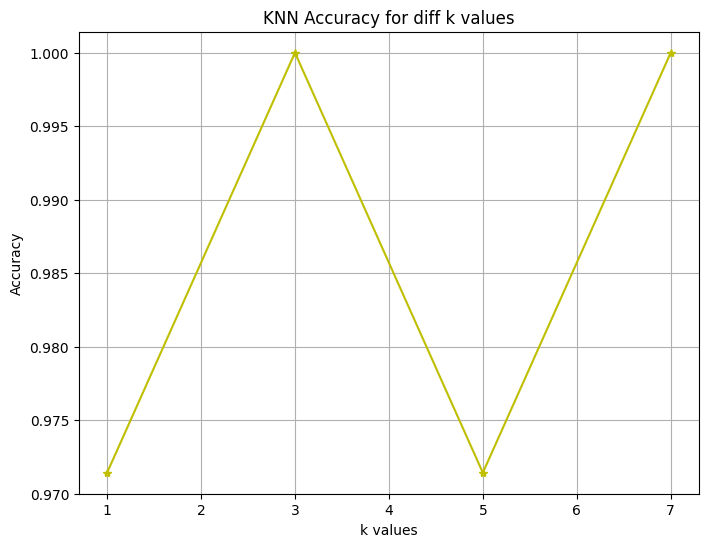

In [32]:
plt.figure(figsize=(8,6))
plt.plot(k_values_list,accuracies,color = "y", marker = "*")
plt.xlabel("k values")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy for diff k values")
plt.grid(True)
plt.show()

In [33]:
#I trained a KNN model using Wine dataset and tested different k values to find the best fit. As you can see in the graph, the model hit a perfect 100% accuracy at both k=3 and k=7.
# Also 97% accuracy is very good and this shows that the 13 chemical constituents in the data are great for distinguishing between the three different cultivars.